In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from glob import glob

from sklearn.model_selection import train_test_split
from sklearn import metrics

import cv2
import gc
import os

import tensorflow as tf
from tensorflow import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')


In [ ]:

import matplotlib.pyplot as plt

!pip install kaggle

# Assuming you have your Kaggle API token uploaded, you can download the dataset:
!kaggle datasets download -d andrewmvd/lung-and-colon-cancer-histopathological-images

# Unzip the downloaded dataset
!unzip lung-and-colon-cancer-histopathological-images.zip



Streaming output truncated to the last 5000 lines.
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc10.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc100.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1000.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1001.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1002.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1003.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1004.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1005.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1006.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1007.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1008.jpeg  
  inflating: lung_c

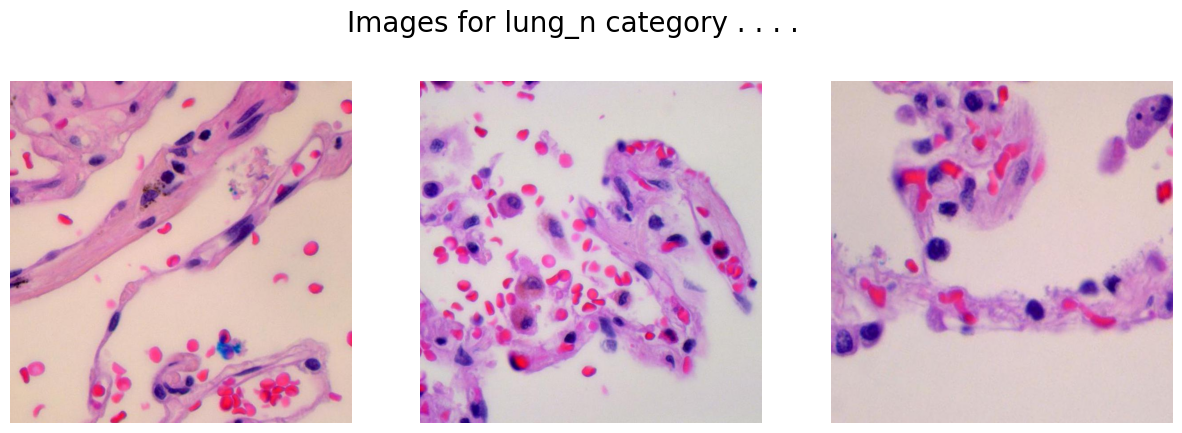

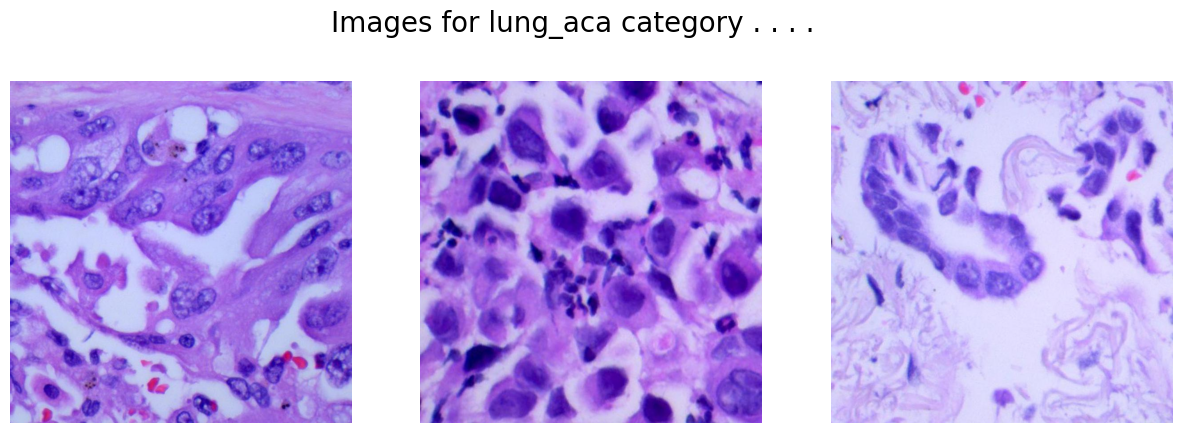

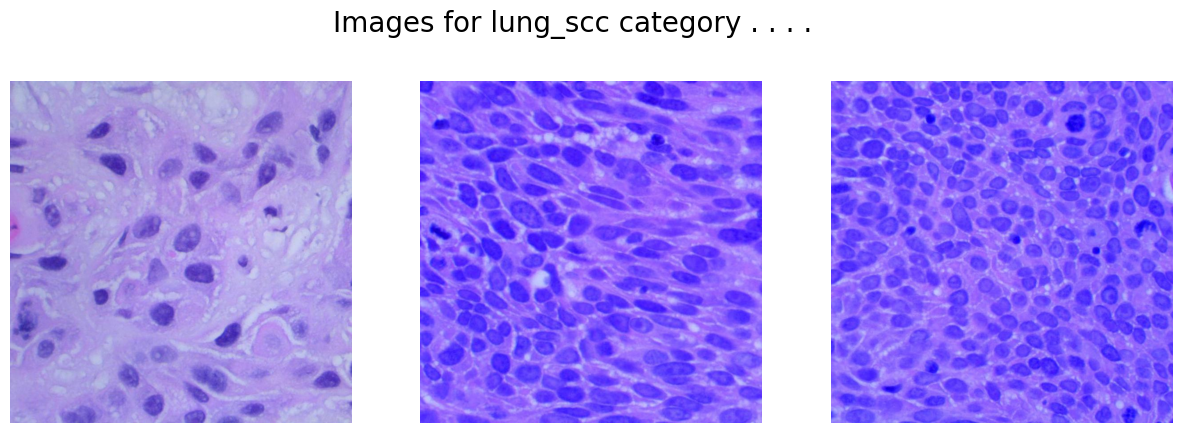

In [ ]:
path = 'lung_colon_image_set/lung_image_sets'
classes = os.listdir(path)
classes

for cat in classes:
	image_dir = f'{path}/{cat}'
	images = os.listdir(image_dir)

	fig, ax = plt.subplots(1, 3, figsize=(15, 5))
	fig.suptitle(f'Images for {cat} category . . . .', fontsize=20)

	for i in range(3):
		k = np.random.randint(0, len(images))
		img = np.array(Image.open(f'{path}/{cat}/{images[k]}'))
		ax[i].imshow(img)
		ax[i].axis('off')
	plt.show()


In [ ]:
IMG_SIZE = 128
SPLIT = 0.2
EPOCHS = 10
BATCH_SIZE = 64
print(classes)


['lung_n', 'lung_aca', 'lung_scc']


# Data Processing

In [ ]:
X = []
Y = []

print(classes)


# Iterate over each class and correctly assign labels
for i, cat in enumerate(classes):  # `i` will be the class label (0, 1, 2)
    images = glob(f'{path}/{cat}/*.jpeg')

    for image in images:
        img = cv2.imread(image)
        if img is not None:
            # Append resized image to X and corresponding class label to Y
            X.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE)))
            Y.append(i)  # `i` corresponds to the class (0, 1, or 2)

X = np.asarray(X)

# Now apply one-hot encoding to the labels
one_hot_encoded_Y = pd.get_dummies(Y).values

# Check the corrected distribution of Y (before one-hot encoding)
print("Corrected labels distribution:", np.bincount(Y))


['lung_n', 'lung_aca', 'lung_scc']
Corrected labels distribution: [5000 5000 5000]


In [ ]:
X_train, X_val, Y_train, Y_val = train_test_split(X, one_hot_encoded_Y,
												test_size = SPLIT)
print(X_train.shape, X_val.shape)
print(Y_train.shape, Y_val.shape)


(12000, 128, 128, 3) (3000, 128, 128, 3)
(12000, 3) (3000, 3)


In [ ]:
model = keras.models.Sequential([
    layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),  # Ensure Flatten layer is correctly placed
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')
])


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Load and preprocess your data as before

# Ensure Y is a NumPy array

# Split the dataset into training and validation sets
X_train, X_val, Y_train, Y_val = train_test_split(X, one_hot_encoded_Y, test_size=SPLIT, random_state=2022)

# Example model architecture
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(3, activation='softmax'))  # Output layer for 3 classes

# Compile the model
model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])

X_train, X_val, Y_train, Y_val = train_test_split(X, one_hot_encoded_Y,
												test_size = SPLIT,
												random_state = 2022)
print(X_train.shape, X_val.shape)
print(Y_train.shape, Y_val.shape)


(12000, 128, 128, 3) (3000, 128, 128, 3)
(12000, 3) (3000, 3)


In [ ]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau


class myCallback(tf.keras.callbacks.Callback):
	def on_epoch_end(self, epoch, logs={}):
		if logs.get('val_accuracy') > 0.90:
			print('\n Validation accuracy has reached upto \
					90% so, stopping further training.')
			self.model.stop_training = True


es = EarlyStopping(patience=3,
				monitor='val_accuracy',
				restore_best_weights=True)

lr = ReduceLROnPlateau(monitor='val_loss',
					patience=2,
					factor=0.5,
					verbose=1)


In [ ]:

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=BATCH_SIZE,
                    epochs=EPOCHS,
                    verbose=1,
                    callbacks=[es, lr, myCallback()])



Epoch 1/10


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'None' of layer 'dense_2' is incompatible with the layer: expected axis -1 of input shape to have value 516128, but received input with shape (None, 127008)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(None, 128, 128, 3), dtype=uint8)
  • training=True
  • mask=None
  • kwargs=<class 'inspect._empty'>

Visualising Data

In [ ]:
history_df = pd.DataFrame(history.history)
print(history_df.head())  # This will show the first few rows of your training history

history_df.loc[:,['loss','val_loss']].plot()
history_df.loc[:,['accuracy','val_accuracy']].plot()
plt.show()


print(Y_train[:5])  # Check the first 5 labels in the training set
print(Y_val[:5])    # Check the first 5 labels in the validation set


